In [1]:
%pip install pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import urllib.request
import zipfile

# 1. Bikin folder data/raw secara otomatis
os.makedirs('../data/raw', exist_ok=True)

# 2. Link asli dataset dari UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"
zip_path = "../data/raw/student.zip"

print("Mulai mendownload dataset dari UCI...")
# 3. Download filenya
urllib.request.urlretrieve(url, zip_path)

print("Mengekstrak file zip...")
# 4. Ekstrak file zip-nya biar kita dapet student-mat.csv
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('../data/raw')

print("BERHASIL! File student-mat.csv sekarang udah siap di folder ../data/raw/")

Mulai mendownload dataset dari UCI...
Mengekstrak file zip...
BERHASIL! File student-mat.csv sekarang udah siap di folder ../data/raw/


In [3]:
# Sel 1: Import library yang dibutuhkan
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Set gaya visualisasi
sns.set_theme(style="whitegrid")

In [5]:
# Sel 2: Langkah 1 & 2 - Siapkan Data dan Tentukan Target
# Memuat data raw dari UCI (pemisah titik koma)
df = pd.read_csv('../data/raw/student-mat.csv', sep=';')

# Membuat target 'tidak_lulus': bernilai 1 jika G3 < 10
df['tidak_lulus'] = (df['G3'] < 10).astype(int)

In [8]:
# Sel 3: Langkah 3 - Pisahkan Data Uji SEKARANG
# Memisahkan 80% train dan 20% test dengan stratify dan random_state=42
train, test = train_test_split(
    df, test_size=0.2, stratify=df['tidak_lulus'], random_state=42
)

# Menyimpan data latih dan uji ke folder processed
train.to_csv('../data/processed/train.csv', index=False)
test.to_csv('../data/processed/test.csv', index=False)

print(f"Data latih disimpan dengan {train.shape[0]} baris.")
print(f"Data uji disimpan dengan {test.shape[0]} baris (DISEGEL).")

Data latih disimpan dengan 316 baris.
Data uji disimpan dengan 79 baris (DISEGEL).


In [9]:
# Sel 4: Langkah 4 - Deskripsikan Data (Hanya Train)
print("==== DESKRIPSI DATA LENGKAP ====")
print(f"Bentuk data latih (train.shape): {train.shape}")
print(f"Bentuk data uji (test.shape): {test.shape}")
print(f"Jumlah Nilai Hilang di Train: {train.isna().sum().sum()}")
print(f"Jumlah Baris Duplikat di Train: {train.duplicated().sum()}")

print("\nProporsi Kelas Target (tidak_lulus) dalam Persen:")
print(train['tidak_lulus'].value_counts(normalize=True) * 100)

==== DESKRIPSI DATA LENGKAP ====
Bentuk data latih (train.shape): (316, 34)
Bentuk data uji (test.shape): (79, 34)
Jumlah Nilai Hilang di Train: 0
Jumlah Baris Duplikat di Train: 0

Proporsi Kelas Target (tidak_lulus) dalam Persen:
tidak_lulus
0    67.088608
1    32.911392
Name: proportion, dtype: float64


C:\Users\Silvia Muflihah\AppData\Local\Temp\ipykernel_18140\4200008112.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x='tidak_lulus', palette='Set2')


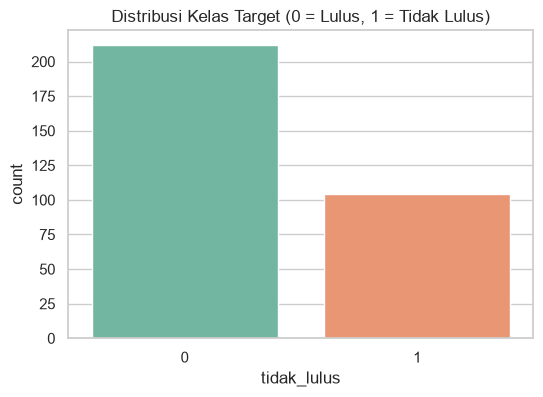

In [10]:
# Sel 5: Langkah 5 - EDA (Grafik 1: Diagram Batang Kelas Target)
plt.figure(figsize=(6, 4))
sns.countplot(data=train, x='tidak_lulus', palette='Set2')
plt.title("Distribusi Kelas Target (0 = Lulus, 1 = Tidak Lulus)")
plt.show()

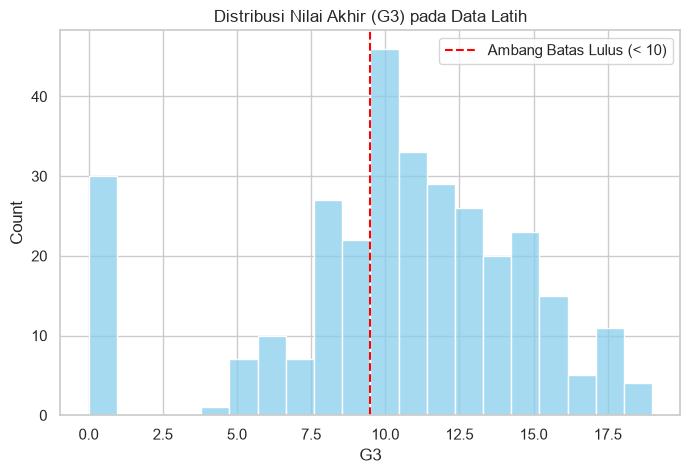

In [11]:
# Sel 6: Langkah 5 - EDA (Grafik 2: Histogram G3 dengan Garis Ambang 10)
plt.figure(figsize=(8, 5))
sns.histplot(train['G3'], bins=20, kde=False, color='skyblue')
plt.axvline(x=9.5, color='red', linestyle='--', label='Ambang Batas Lulus (< 10)')
plt.title("Distribusi Nilai Akhir (G3) pada Data Latih")
plt.legend()
plt.show()

C:\Users\Silvia Muflihah\AppData\Local\Temp\ipykernel_18140\169794276.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='tidak_lulus', y='absences', ax=axes[0], palette='Set2')


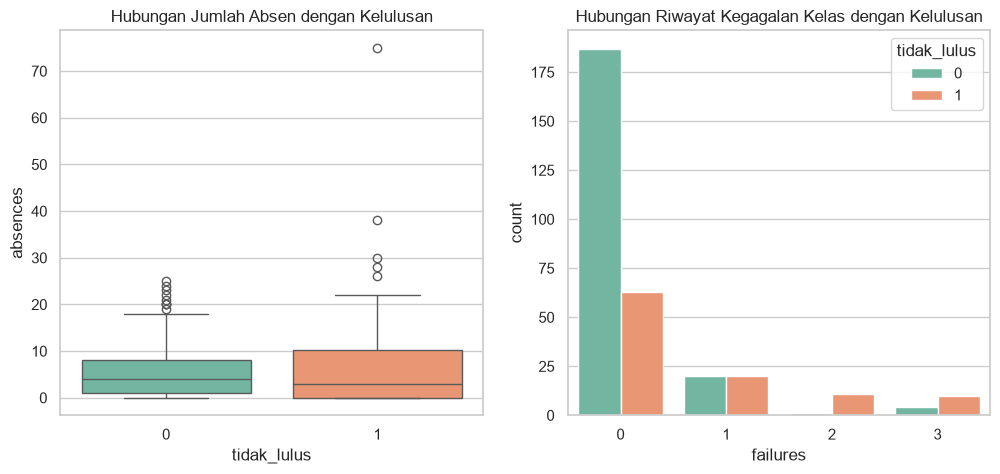

In [12]:
# Sel 7: Langkah 5 - EDA (Grafik 3: Hubungan Fitur dengan Target)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=train, x='tidak_lulus', y='absences', ax=axes[0], palette='Set2')
axes[0].set_title("Hubungan Jumlah Absen dengan Kelulusan")

sns.countplot(data=train, x='failures', hue='tidak_lulus', ax=axes[1], palette='Set2')
axes[1].set_title("Hubungan Riwayat Kegagalan Kelas dengan Kelulusan")
plt.show()

In [13]:
# Sel 8: Langkah 6 - Tulis columns.json
# Menyiapkan kontrak fitur untuk anggota B, C, dan D
fitur = [c for c in train.columns if c not in ['G3', 'tidak_lulus']]
cat_cols = [c for c in fitur if train[c].dtype == 'object']
num_cols = [c for c in fitur if c not in cat_cols]
tanpa_g = [c for c in fitur if c not in ['G1', 'G2']]

kontrak = {
    'target': 'tidak_lulus',
    'fitur_dengan_g': fitur,
    'fitur_tanpa_g': tanpa_g,
    'cat_cols': cat_cols,
    'num_cols': num_cols,
}

# Menyimpan ke format JSON
with open('../data/processed/columns.json', 'w') as f:
    json.dump(kontrak, f, indent=2)
    
print("==== BERHASIL ====")
print("File columns.json berhasil dibuat di ../data/processed/")

==== BERHASIL ====
File columns.json berhasil dibuat di ../data/processed/


In [7]:
import os
os.makedirs('../data/processed', exist_ok=True)